In [6]:
# %pip install pingouin
# %pip install openpyxl
# %pip install "pingouin==0.5.3"
# %pip install "pandas<3.0"

In [7]:
"""
Generate the five task-evaluation figures from the Responses sheet.
Outputs to data-visuals/task/*.png
"""
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import stats
import pingouin as pg

mpl.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
OUT = "data-visuals/task"
os.makedirs(OUT, exist_ok=True)
XLSX = "AI_Reading_Study_20261123.xlsx"

# ----------------------------------------------------------------------------
# 1. Load and reshape
# ----------------------------------------------------------------------------
r = pd.read_excel(XLSX, sheet_name="Responses", header=1)
r = r[r["Participant"].astype(str).str.match(r"P\d{2}")].reset_index(drop=True)

LIKERT = {"Strongly Disagree":1, "Disagree":2, "Neutral":3, "Agree":4, "Strongly Agree":5}

# Map each of the four rating blocks to the nine item columns.
# Column names follow the Responses header; the ".1/.2/.3" suffixes mark
# the 2nd/3rd/4th repetitions. If your header differs slightly, check here.
BLOCKS = {
    "T1pre":  ["Trust: confident it is correct",
               "Trust: response is reliable",
               "Trust: would act without checking",
               "Accuracy: reflects the paper",
               "Accuracy: captures key points",
               "Accuracy: few or no errors",
               "Comprehension: helped me understand",
               "Comprehension: could explain main idea",
               "Comprehension: easy to follow"],
    "T1post": ["Trust: confident it is correct.1",
               "Trust: response is reliable.1",
               "Trust: would act without checking.1",
               "Accuracy: reflects the paper.1",
               "Accuracy: captures key points.1",
               "Accuracy: few or no errors.1",
               "Comprehension: helped me understand.1",
               "Comprehension: could explain main idea.1",
               "Comprehension: easy to follow.1"],
    "T2pre":  ["Trust: confident it is correct.2",
               "Trust: response is reliable.2",
               "Trust: would act without checking.2",
               "Accuracy: reflects the paper.2",
               "Accuracy: captures key points.2",
               "Accuracy: few or no errors.2",
               "Comprehension: helped me understand.2",
               "Comprehension: could explain main idea.2",
               "Comprehension: easy to follow.2"],
    "T2post": ["Trust: confident it is correct.3",
               "Trust: response is reliable.3",
               "Trust: would act without checking.3",
               "Accuracy: reflects the paper.3",
               "Accuracy: captures key points.3",
               "Accuracy: few or no errors.3",
               "Comprehension: helped me understand.3",
               "Comprehension: could explain main idea.3",
               "Comprehension: easy to follow.3"],
}
SHORT = ["TR1","TR2","TR3","AC1","AC2","AC3","CO1","CO2","CO3"]

rows = []
for cell, cols in BLOCKS.items():
    sub = r[cols].apply(lambda s: s.map(LIKERT))
    for i, row in sub.iterrows():
        rec = {"PID": r.loc[i, "Participant"],
               "Status": r.loc[i, "Student status"],
               "cell": cell}
        rec.update(dict(zip(SHORT, row.values)))
        rows.append(rec)
L = pd.DataFrame(rows)
L["Task"]   = L["cell"].str[:2].map({"T1":"Task 1", "T2":"Task 2"})
L["Timing"] = L["cell"].str[2:].map({"pre":"Before", "post":"After"})

# Composites
L["Trust2"] = L[["TR1","TR2"]].mean(axis=1)          # calibrated trust
L["Trust3"] = L[["TR1","TR2","TR3"]].mean(axis=1)    # workbook version
L["Acc"]    = L[["AC1","AC2","AC3"]].mean(axis=1)
L["Comp"]   = L[["CO1","CO2","CO3"]].mean(axis=1)

# Ordering helpers
TASK_ORDER   = ["Task 1","Task 2"]
TIMING_ORDER = ["Before","After"]

# ----------------------------------------------------------------------------
# Figure 1 — Before → After by construct, with individual trajectories
# ----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
COL = {"Task 1":"#604CB0", "Task 2":"#52B3DD"}
for ax, (dv, title) in zip(axes, [("Trust2","Trust (TR1–2)"),
                                  ("Acc","Perceived accuracy"),
                                  ("Comp","Comprehension")]):
    for task in TASK_ORDER:
        s = L[L.Task == task]
        # individual spaghetti
        for _, g in s.groupby("PID"):
            g = g.set_index("Timing").reindex(TIMING_ORDER)
            ax.plot([0, 1], g[dv].values, color=COL[task], alpha=.18, lw=.8, zorder=1)
        means = s.groupby("Timing")[dv].mean().reindex(TIMING_ORDER)
        sems  = s.groupby("Timing")[dv].sem().reindex(TIMING_ORDER)
        ax.errorbar([0, 1], means.values, yerr=sems.values, color=COL[task],
                    marker="o", lw=2.6, ms=8, capsize=4, zorder=3, label=task)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Before reading","After reading"])
    ax.axhline(3, color="grey", lw=.8, ls="--")
    ax.set_title(title); ax.set_ylim(1, 5.4)
    ax.set_ylabel("Rating (1–5)" if ax is axes[0] else "")
    ax.legend(frameon=False, fontsize=9)
fig.suptitle("Before → After reading the original paper: group means (± SEM) and individual participants\n"
             "2 × 2 RM-ANOVA, N = 13 — no Task/Timing/interaction effect reaches p < .05", fontsize=11)
fig.tight_layout(rect=[0, 0, 1, .90])
fig.savefig(f"{OUT}/task-before-after.png", dpi=200); plt.close(fig)

# ----------------------------------------------------------------------------
# Figure 2 — Item-level profile, pooled across four blocks
# ----------------------------------------------------------------------------
Lm = L.melt(id_vars=["PID","Status","Task","Timing"],
            value_vars=SHORT, var_name="Item", value_name="Score")
gm = Lm.groupby("Item")["Score"].agg(["mean","sem"]).reindex(SHORT)
item_labels = ["TR1 confident", "TR2 reliable", "TR3 act unchecked",
               "AC1 reflects paper", "AC2 key points", "AC3 few/no errors",
               "CO1 helped understand", "CO2 could explain", "CO3 easy to follow"]
colours = ["#4C72B0" if it.startswith("TR") else
           "#DD8452" if it.startswith("AC") else "#55A868" for it in SHORT]

fig, ax = plt.subplots(figsize=(8.5, 4.8))
x = np.arange(len(SHORT))
ax.bar(x, gm["mean"].values, yerr=gm["sem"].values, capsize=4,
       color=colours, edgecolor="white", linewidth=.5)
ax.axhline(3, color="grey", ls="--", lw=.8)
ax.set_xticks(x); ax.set_xticklabels(item_labels, rotation=30, ha="right", fontsize=9)
ax.set_ylabel("Mean rating (1–5)")
ax.set_title("Item-level means pooled across all four rating blocks (n = 52)\n"
             "Blue = Trust · orange = Accuracy · green = Comprehension")
ax.set_ylim(1, 5)
fig.tight_layout(); fig.savefig(f"{OUT}/task-item-profile.png", dpi=200); plt.close(fig)

In [8]:
# ----------------------------------------------------------------------------
# Figure 3 — Local vs International
# ----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
SCOL = {"International":"#0D3E6B", "Local":"#A94646"}
xs_map = {("Task 1","Before"):0, ("Task 1","After"):1,
          ("Task 2","Before"):2, ("Task 2","After"):3}
for ax, (dv, title) in zip(axes, [("Trust2","Trust (TR1–2)"),
                                  ("Acc","Perceived accuracy"),
                                  ("Comp","Comprehension")]):
    for grp, colour in SCOL.items():
        s = L[L.Status == grp]
        m = s.groupby(["Task","Timing"])[dv].mean()
        e = s.groupby(["Task","Timing"])[dv].sem()
        xs = [xs_map[k] for k in m.index]
        ax.errorbar(xs, m.values, yerr=e.values, color=colour,
                    marker="o", lw=2.4, ms=7, capsize=3, label=grp)
    ax.axvline(1.5, color="grey", lw=.7, ls=":")
    ax.axhline(3, color="grey", lw=.8, ls="--")
    ax.set_xticks([0,1,2,3])
    ax.set_xticklabels(["T1\nBefore","T1\nAfter","T2\nBefore","T2\nAfter"], fontsize=9)
    ax.set_title(title); ax.set_ylim(1, 5.4)
    ax.set_ylabel("Rating (1–5)" if ax is axes[0] else "")
    if ax is axes[0]: ax.legend(frameon=False, fontsize=9)
fig.suptitle("Local (n = 9) vs International (n = 4): construct ratings across task and timing\n"
             "No Status main effect or interaction reaches p < .05 (mixed ANOVA, N = 13)", fontsize=11)
fig.tight_layout(rect=[0, 0, 1, .90])
fig.savefig(f"{OUT}/task-status-groups.png", dpi=200); plt.close(fig)

In [9]:
# ----------------------------------------------------------------------------
# Figure 4 — Effect sizes (dot plot)
# ----------------------------------------------------------------------------
# rows_eff = []
# for dv, name in [("Trust2","Trust (TR1–2)"), ("Trust3","Trust (TR1–3)"),
#                  ("Acc","Accuracy"), ("Comp","Comprehension")]:
#     aov = pg.rm_anova(data=L, dv=dv, within=["Task","Timing"],
#                       subject="PID", detailed=True)
#     for _, r2 in aov.iterrows():
#         if r2["Source"] in ("Task","Timing","Task * Timing"):
#             rows_eff.append({"Construct":name, "Effect":r2["Source"],
#                              "eta2p":r2["np2"], "p":r2["p-unc"]})
# E = pd.DataFrame(rows_eff)
# markers = {"Task":"o","Timing":"s","Task * Timing":"^"}
# fig, ax = plt.subplots(figsize=(8.5, 4.8))
# constructs = list(dict.fromkeys(E.Construct))
# for i, c in enumerate(constructs):
#     sub = E[E.Construct == c]
#     for j, eff in enumerate(["Task","Timing","Task * Timing"]):
#         r2 = sub[sub.Effect == eff].iloc[0]
#         y = i + (j - 1) * 0.22
#         ax.scatter(r2.eta2p, y, marker=markers[eff], s=75, label=eff if i == 0 else "")
#         ax.text(r2.eta2p + .006, y, f"η²={r2.eta2p:.2f}, p={r2.p:.2f}",
#                 va="center", fontsize=8)
# for v, ls in [(.01,":"), (.06,"--"), (.14,"-")]:
#     ax.axvline(v, color="grey", ls=ls, lw=.8)
# ax.set_yticks(range(len(constructs))); ax.set_yticklabels(constructs)
# ax.set_xlabel("Partial η²")
# ax.set_title("ANOVA effect sizes with p-values (2 × 2 RM-ANOVA, N = 13)\n"
#              "dotted = small (.01), dashed = medium (.06), solid = large (.14)")
# ax.legend(frameon=False, fontsize=9, loc="lower right")
# fig.tight_layout(); fig.savefig(f"{OUT}/task-effect-sizes.png", dpi=200); plt.close(fig)

In [10]:
# ----------------------------------------------------------------------------
# Figure 5 — Post-task retrospective (two panels)
# ----------------------------------------------------------------------------
r["_change"] = r["Change in trust in AI"].map({
    "Decreased a lot":-2, "Decreased somewhat":-1, "Stayed the same":0,
    "Increased somewhat":1, "Increased a lot":2})
r["_accuracy"] = r["Judged accuracy of AI outputs"].map({
    "Not at all":1, "Slightly":2, "Moderately":3, "Very":4, "Extremely":5})

change_counts = (r["Change in trust in AI"]
                 .value_counts()
                 .reindex(["Decreased a lot","Decreased somewhat","Stayed the same",
                           "Increased somewhat","Increased a lot"]).fillna(0))
acc_counts    = (r["Judged accuracy of AI outputs"]
                 .value_counts()
                 .reindex(["Not at all","Slightly","Moderately","Very","Extremely"]).fillna(0))

In [11]:

# fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
# bars = axes[0].bar(range(len(change_counts)), change_counts.values,
#                       color=["#4C72B0"])
# axes[0].set_xticks(range(len(change_counts)))
# axes[0].set_xticklabels(["Decreased\na lot","Decreased\nsomewhat","Stayed\nthe same",
#                          "Increased\nsomewhat","Increased\na lot"], fontsize=8)
# axes[0].set_ylabel("Participants")
# axes[0].set_title("Change in trust in AI after both tasks")
# for b, v in zip(bars, change_counts.values):
#     axes[0].text(b.get_x() + b.get_width()/2, v + .1, int(v), ha="center", fontsize=9)
# axes[0].axhline(0, color="black", lw=.6)

# bars = axes[1].bar(range(len(acc_counts)), acc_counts.values,
#                    color=["#DD8452"])
# axes[1].set_xticks(range(len(acc_counts)))
# axes[1].set_xticklabels(acc_counts.index, fontsize=8)
# axes[1].set_ylabel("Participants")
# axes[1].set_title("Judged accuracy of AI outputs after checking against both papers")
# for b, v in zip(bars, acc_counts.values):
#     axes[1].text(b.get_x() + b.get_width()/2, v + .1, int(v), ha="center", fontsize=9)
# axes[1].axhline(0, color="black", lw=.6)

# fig.suptitle("Post-task retrospective judgements (N = 13)", fontsize=11)
# fig.tight_layout(rect=[0, 0, 1, .93])
# fig.savefig(f"{OUT}/task-posttask.png", dpi=200); plt.close(fig)

# print("Wrote 5 figures to", OUT)
# for f in sorted(os.listdir(OUT)):
#     print("  ", f)

In [12]:
from statsmodels.stats.anova import AnovaRM

# 对每个因变量分别跑 2×2 重复测量 ANOVA
for dv, name in [("Trust2", "Trust (TR1–2)"), ("Trust3", "Trust (TR1–3)"),
                 ("Acc", "Accuracy"), ("Comp", "Comprehension")]:
    aov = AnovaRM(data=L, depvar=dv, subject="PID", within=["Task", "Timing"])
    result = aov.fit()
    print(f"\n=== {name} ===")
    print(result.anova_table)


=== Trust (TR1–2) ===
              F Value  Num DF  Den DF    Pr > F
Task         2.150442     1.0    12.0  0.168239
Timing       0.790323     1.0    12.0  0.391475
Task:Timing  0.206107     1.0    12.0  0.657938

=== Trust (TR1–3) ===
              F Value  Num DF  Den DF    Pr > F
Task         3.443329     1.0    12.0  0.088224
Timing       1.015276     1.0    12.0  0.333528
Task:Timing  1.121495     1.0    12.0  0.310448

=== Accuracy ===
              F Value  Num DF  Den DF    Pr > F
Task         4.772932     1.0    12.0  0.049475
Timing       0.516472     1.0    12.0  0.486109
Task:Timing  0.096257     1.0    12.0  0.761691

=== Comprehension ===
              F Value  Num DF  Den DF    Pr > F
Task         3.096774     1.0    12.0  0.103891
Timing       3.552870     1.0    12.0  0.083884
Task:Timing  0.214765     1.0    12.0  0.651351


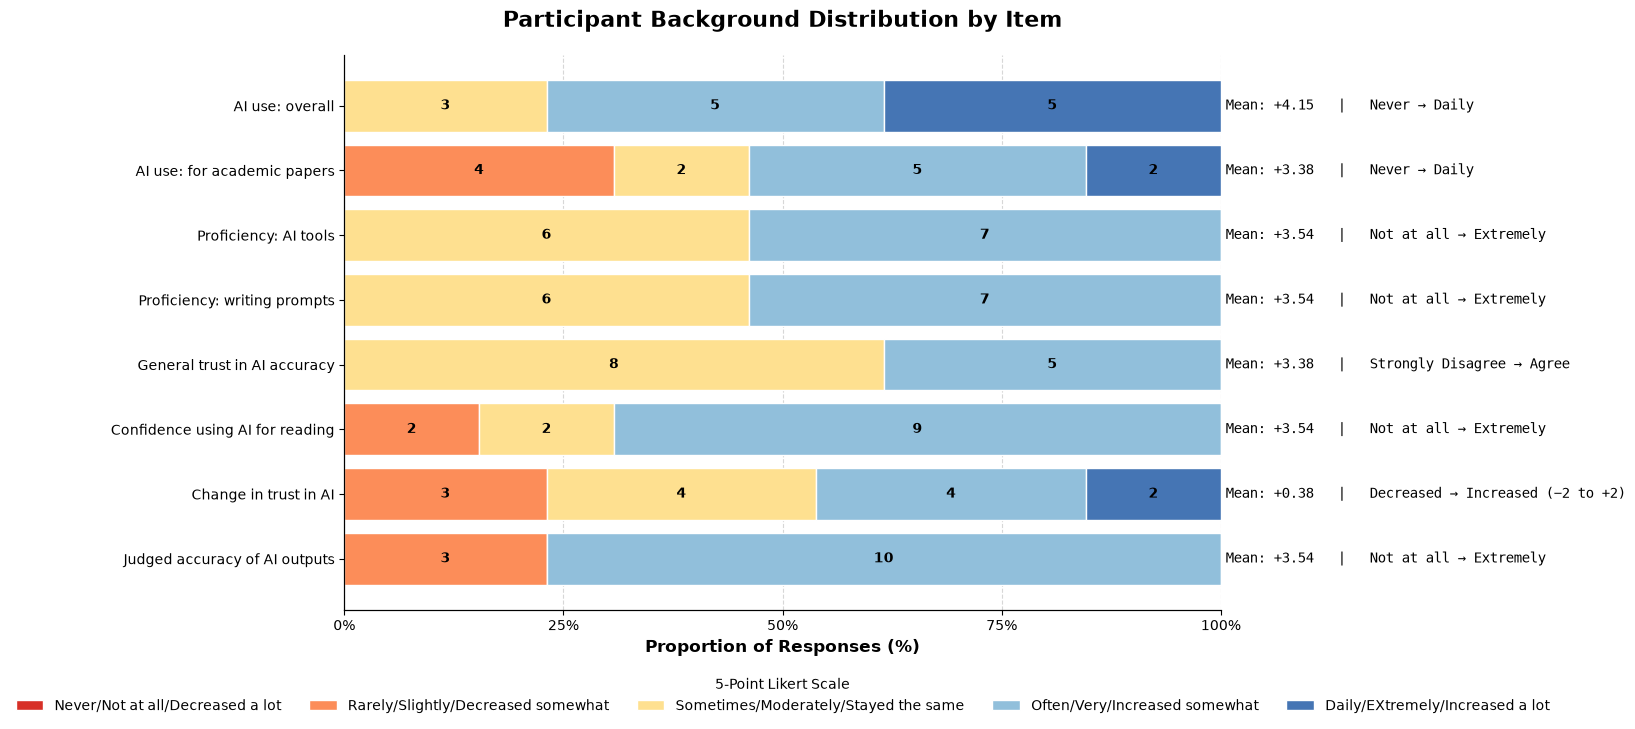

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. The Data (Task difficulty removed)
data = {
    "Question": [
        "AI use: overall",
        "AI use: for academic papers",
        "Proficiency: AI tools",
        "Proficiency: writing prompts",
        "General trust in AI accuracy",
        "Confidence using AI for reading",
        "Change in trust in AI",
        "Judged accuracy of AI outputs"
    ],
    "1": [0, 0, 0, 0, 0, 0, 0, 0],
    "2": [0, 4, 0, 0, 0, 2, 3, 3],
    "3": [3, 2, 6, 6, 8, 2, 4, 0],
    "4": [5, 5, 7, 7, 5, 9, 4, 10],
    "5": [5, 2, 0, 0, 0, 0, 2, 0],
    "Mean": [4.15, 3.38, 3.54, 3.54, 3.38, 3.54, 0.38, 3.54],
    "Scale": [
        "Never → Daily", "Never → Daily", 
        "Not at all → Extremely", "Not at all → Extremely", 
        "Strongly Disagree → Agree", "Not at all → Extremely", 
        "Decreased → Increased (−2 to +2)", "Not at all → Extremely"
    ]
}

df = pd.DataFrame(data)

# 2. Prepare the data for plotting
# Calculate the total N for each row to make it 100% stacked
df['Total'] = df[['1', '2', '3', '4', '5']].sum(axis=1)
counts = df[['1', '2', '3', '4', '5']].div(df['Total'], axis=0) * 100

# 3. Setup the Plot
fig, ax = plt.subplots(figsize=(15, 7.5))

# Colors representing the Likert scale 
# Using a diverging palette: Red (1) to Blue (5)
colors = ['#d73027', '#fc8d59', '#fee090', '#91bfdb', '#4575b4']
labels = ['Never/Not at all/Decreased a lot', 'Rarely/Slightly/Decreased somewhat', 
          'Sometimes/Moderately/Stayed the same', 'Often/Very/Increased somewhat', 'Daily/EXtremely/Increased a lot']

# Plot the stacked bars
left = np.zeros(len(df))
for i, col in enumerate(['1', '2', '3', '4', '5']):
    bars = ax.barh(df['Question'], counts[col], left=left, color=colors[i], label=f"{labels[i]}", edgecolor='white')
    
    # Add count labels inside the bars if the segment is large enough (> 5%)
    for bar, count in zip(bars, df[col]):
        if count > 0:
            width = bar.get_width()
            if width > 5: # Only show text if bar segment is wide enough
                ax.text(bar.get_x() + bar.get_width()/2, bar.get_y() + bar.get_height()/2, 
                        str(count), ha='center', va='center', color='black', fontsize=10, fontweight='bold')
    left += counts[col]

# 4. Formatting the Chart
ax.set_xlim(0, 100)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xticklabels(['0%', '25%', '50%', '75%', '100%'])
ax.set_xlabel('Proportion of Responses (%)', fontsize=12, fontweight='bold')
ax.set_title('Participant Background Distribution by Item', fontsize=16, fontweight='bold', pad=20)

# Invert Y-axis so the first question is at the top
ax.invert_yaxis()

# Add the Mean and Scale columns on the right side
ax2 = ax.twinx()
ax2.set_ylim(ax.get_ylim())
ax2.set_yticks(range(len(df)))

# Create custom labels combining Mean and Scale
right_labels = [f"Mean: {m:+.2f}   |   {s}" for m, s in zip(df['Mean'], df['Scale'])]
ax2.set_yticklabels(right_labels, fontsize=10, va='center', fontfamily='monospace')
ax2.tick_params(axis='y', length=0) # Hide tick marks

# Add grid lines
ax.grid(axis='x', linestyle='--', alpha=0.5, zorder=0)
ax.set_axisbelow(True)

# Move the legend outside the plot
ax.legend(title='5-Point Likert Scale', loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=5, frameon=False)

# Adjust layout
plt.tight_layout()
plt.subplots_adjust(bottom=0.18, right=0.75) # Make room for legend and right-side text

# Save the figure
plt.savefig('survey_responses_chart.png', dpi=300, bbox_inches='tight')
plt.show()